In [1]:
#Importacion de librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Creacion del data frame
df = pd.read_csv("Spotify_Tracks_Dataset.csv")
df.head(2)

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.461,...,-6.746,0,0.1430,0.0322,0.000001,0.358,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.166,...,-17.235,1,0.0763,0.9240,0.000006,0.101,0.267,77.489,4,acoustic


In [3]:
#Visualizacion de la informacion del Data Frame para ubicar nulos.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

In [4]:
#Visualizacion de la descripcion del Dta Frame para revisar los tipos de las columnas y sus variables.
df.describe()

,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,56999.500000,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,32909.109681,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28499.750000,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,56999.500000,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,85499.250000,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,113999.000000,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


In [5]:
df.isnull().sum()

,0
Unnamed: 0,0
track_id,0
artists,1
album_name,1
track_name,1
popularity,0
duration_ms,0
explicit,0
danceability,0
energy,0


In [6]:
# Eliminacion de la fila con datos nulos debido a que solo es una.
df = df.dropna(subset=['artists', 'album_name', 'track_name'])

# Verificacion de nulos en el DataFrame
df.isnull().sum()

,0
Unnamed: 0,0
track_id,0
artists,0
album_name,0
track_name,0
popularity,0
duration_ms,0
explicit,0
danceability,0
energy,0


In [25]:
#Eliminar columnna duration_ms , ya que el mapa de correlacion muestra una correlación de 1 con duration_min
df = df.drop(columns=['duration_ms'])

KeyError: "['duration_ms'] not found in axis"

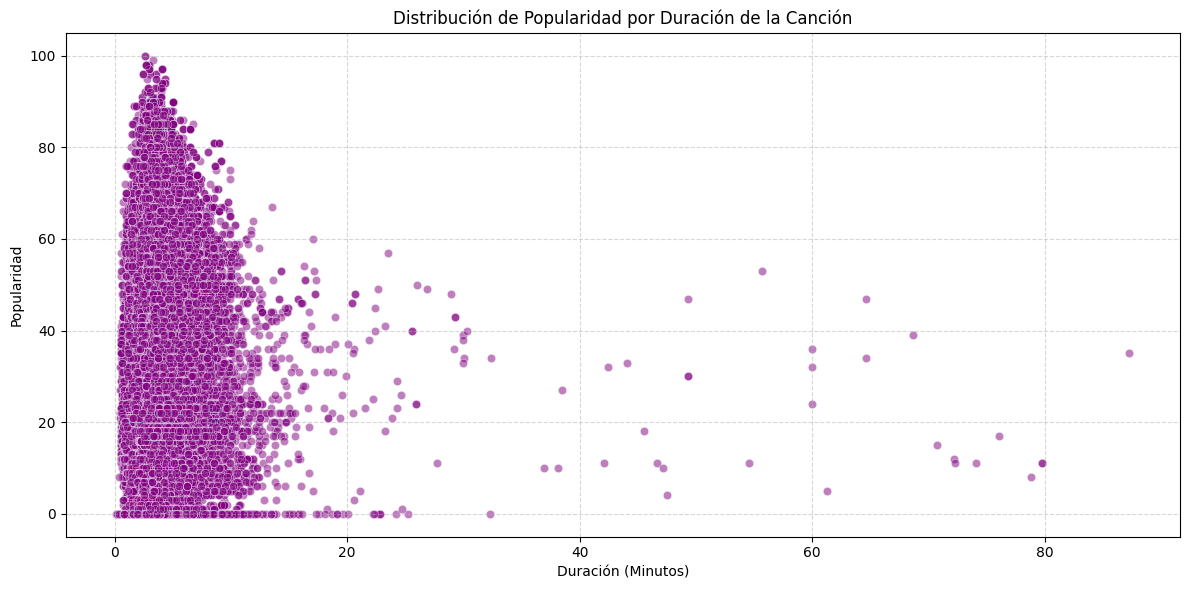

In [7]:
# Grafico para observar la distribucion de la popularidad de las cancion por el tiempo de duracion, para observar outliers.

# Convertimos la duración de milisegundos a minutos para facilitar la interpretación del gráfico
df['duration_min'] = df['duration_ms'] / 60000

# Crear el gráfico de dispersión
plt.figure(figsize=(12, 6))
sns.scatterplot(data=df, x='duration_min', y='popularity', alpha=0.5, color='purple')

plt.title('Distribución de Popularidad por Duración de la Canción')
plt.xlabel('Duración (Minutos)')
plt.ylabel('Popularidad')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

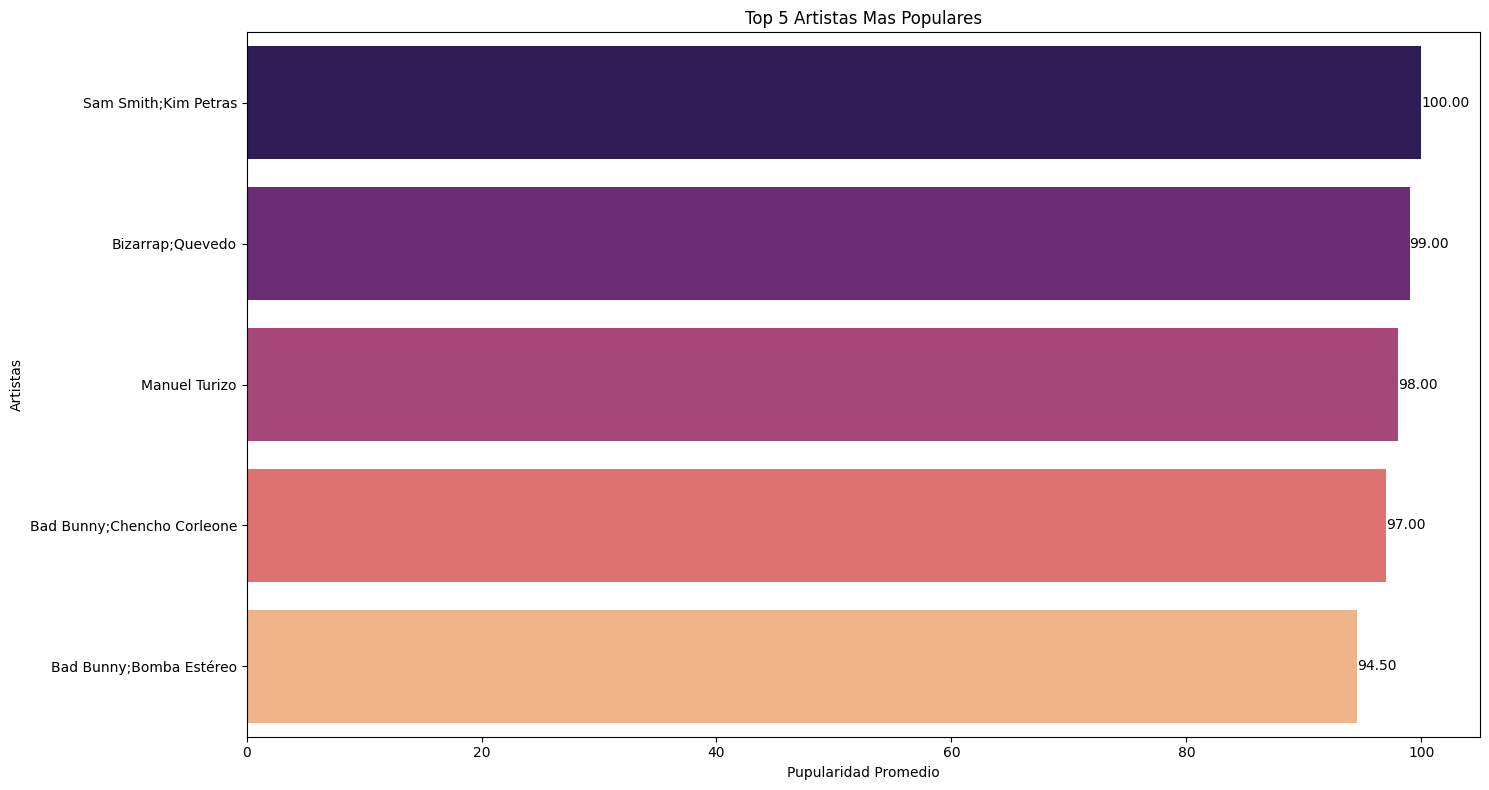

In [8]:


# Agrupacion de artistas por popularidad
artist_popularity = df.groupby('artists')['popularity'].mean().sort_values(ascending=False).reset_index()

# Seleccion de solo los 5 primeros artistas
artist_popularity_top5 = artist_popularity.head(5)

plt.figure(figsize=(15, 8))
sns.barplot(x='popularity', y='artists', data=artist_popularity_top5, palette='magma', hue='artists', legend=False)

for index, row in artist_popularity_top5.iterrows():
    plt.text(row.popularity, index, f'{row.popularity:.2f}', color='black', ha="left", va="center")

plt.title('Top 5 Artistas Mas Populares')
plt.xlabel('Pupularidad Promedio')
plt.ylabel('Artistas')
plt.tight_layout()
plt.show()

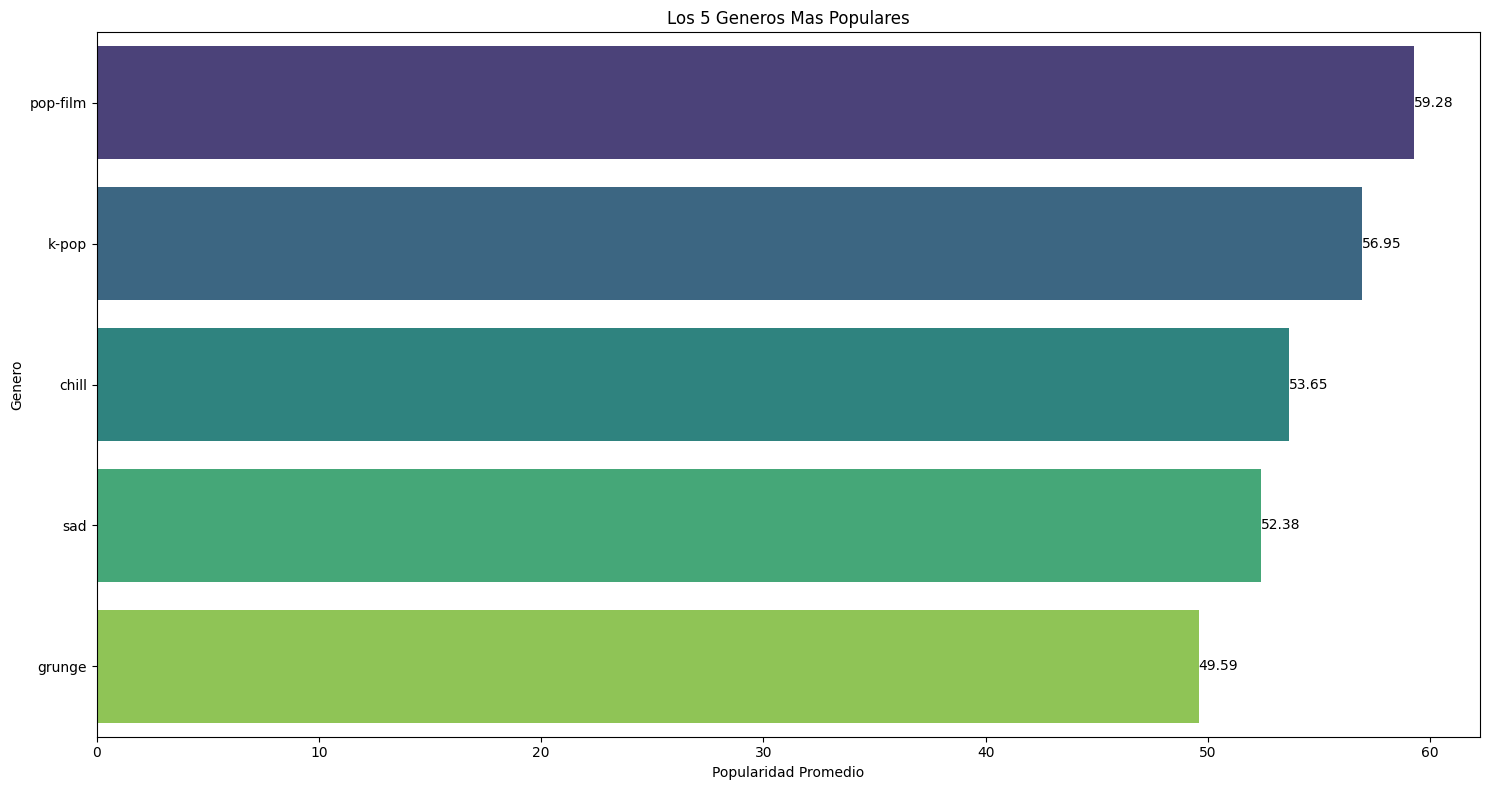

In [9]:


# Mostrar los generos mas populares
genre_popularity = df.groupby('track_genre')['popularity'].mean().sort_values(ascending=False).reset_index()

# Mostrar solo los 5 generos mas populares.
genre_popularity_top5 = genre_popularity.head(5)

plt.figure(figsize=(15, 8))
sns.barplot(x='popularity', y='track_genre', data=genre_popularity_top5, palette='viridis', hue='track_genre', legend=False)

# Adicion de etiquetas que muestren el valor del Y sobre las barras.
for index, row in genre_popularity_top5.iterrows():
    plt.text(row.popularity, index, f'{row.popularity:.2f}', color='black', ha="left", va="center")

plt.title('Los 5 Generos Mas Populares')
plt.xlabel('Popularidad Promedio')
plt.ylabel('Genero')
plt.tight_layout()
plt.show()

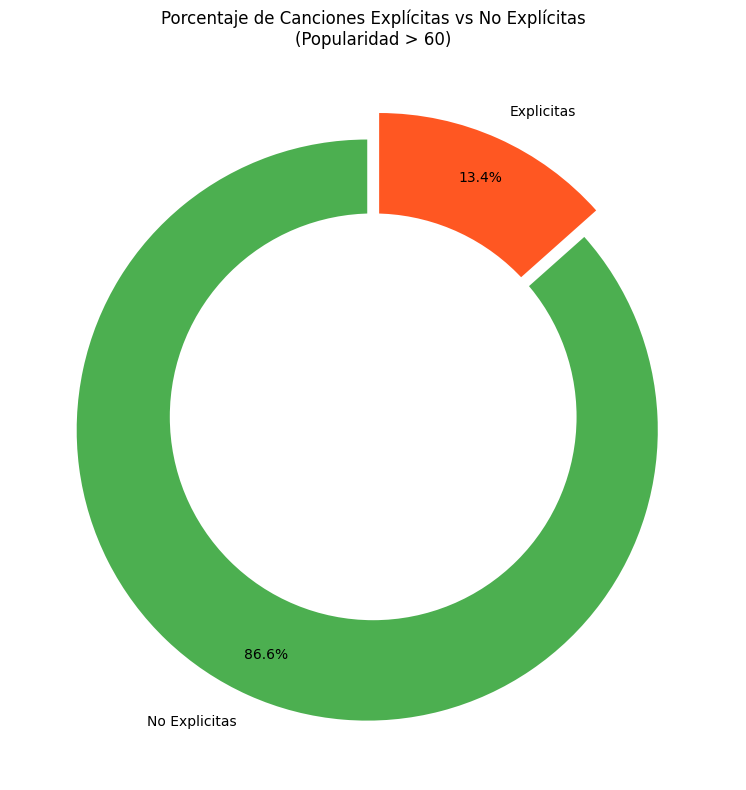

In [10]:
# Porcentaje de comparacion de canciones explicitas y no explicitas sobre el 60% de popularidad.

#Filtrado de canciones con popularidad mayor a 60
df_popular = df[df['popularity'] > 60]

# Contar las canciones explicitas
explicit_counts = df_popular['explicit'].value_counts()

# Configurar etiquetas y colores
labels = ['No Explicitas', 'Explicitas']
sizes = [explicit_counts.get(False, 0), explicit_counts.get(True, 0)]
colors = ['#4CAF50', '#FF5722']
explode = (0.05, 0.05)

# Crear el gráfico de rosquilla
plt.figure(figsize=(8, 8))
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90, pctdistance=0.85)

centre_circle = plt.Circle((0,0),0.70,fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title('Porcentaje de Canciones Explícitas vs No Explícitas\n(Popularidad > 60)')
plt.tight_layout()
plt.show()

In [16]:
# Numero de elementos unicos
artistas_unicos = df['artists'].nunique()
album_unicos = df['album_name'].nunique()
canciones_unicas = df['track_name'].nunique()

print(f"Numero de artistas unicos: {artistas_unicos}")
print(f"Numero de nombres de album unicos: {album_unicos}")
print(f"Numero de nombres de canciones unicas: {canciones_unicas}")

Numero de artistas unicos: 31437
Numero de nombres de album unicos: 46589
Numero de nombres de canciones unicas: 73608


In [17]:
# Popularidad promedio de las canciones
popularidad_promedio = df['popularity'].mean()
print(f"Popularidad promedio de las canciones: {popularidad_promedio:.2f}")

Popularidad promedio de las canciones: 33.24


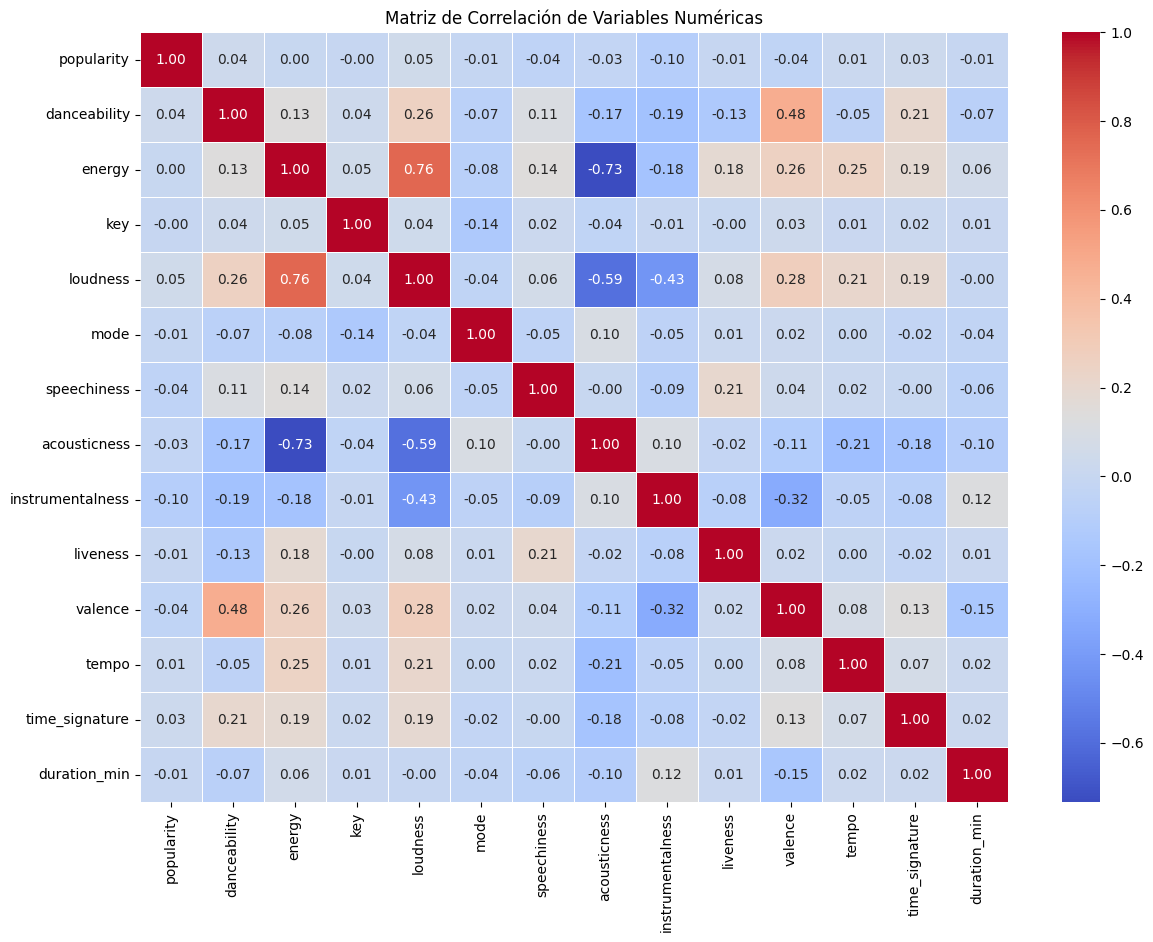

In [26]:
#Columnas umericas
numerical_df = df.select_dtypes(include=[np.number])

# Eliminar la columna 'Unnamed: 0'
if 'Unnamed: 0' in numerical_df.columns:
    numerical_df = numerical_df.drop(columns=['Unnamed: 0'])

# Calcular la matriz de correlación
matriz_corr = numerical_df.corr()

# Visualizar
plt.figure(figsize=(14, 10))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Matriz de Correlación de Variables Numéricas')
plt.show()

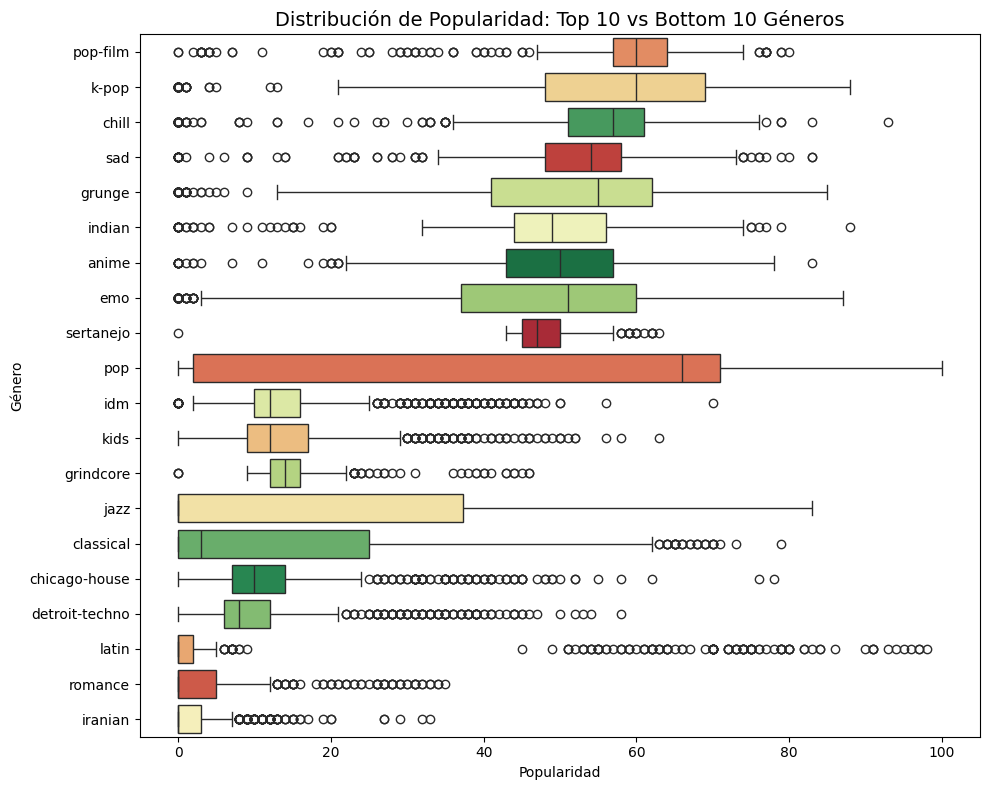

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

# Top 10 y bottom 10 géneros según popularidad promedio
promedio_por_genero = df.groupby('track_genre')['popularity'].mean().sort_values(ascending=False)
orden = list(promedio_por_genero.head(10).index) + list(promedio_por_genero.tail(10).index)
subconjunto = df[df['track_genre'].isin(orden)]

# Boxplot
plt.figure(figsize=(10, 8))
sns.boxplot(data=subconjunto, x='popularity', y='track_genre', order=orden,
            hue='track_genre', palette='RdYlGn_r', legend=False)
plt.title('Distribución de Popularidad: Top 10 vs Bottom 10 Géneros', fontsize=14)
plt.xlabel('Popularidad')
plt.ylabel('Género')
plt.tight_layout()
plt.show()